# All 54 Days

In [41]:
import pandas as pd

df1 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row1_thr_0.0005.parquet")

# Add "real time" column: start at 20250902141500, increment by 6 sec per row, keep as numeric format
start_time = pd.to_datetime("20250902141500", format="%Y%m%d%H%M%S")
real_times = [int((start_time + pd.Timedelta(seconds=6*i)).strftime("%Y%m%d%H%M%S")) for i in range(len(df1))]
df1["real time"] = real_times

df1.to_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row1_with_realtime_0.0005.parquet")

In [43]:
import pandas as pd

df2 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row2_thr_0.0005.parquet")

# Add "real time" column: start at 20250902141500, increment by 6 sec per row, keep as numeric format
start_time = pd.to_datetime("20250914072000", format="%Y%m%d%H%M%S")
real_times = [int((start_time + pd.Timedelta(seconds=6*i)).strftime("%Y%m%d%H%M%S")) for i in range(len(df2))]
df2["real time"] = real_times

df2.to_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row2_with_realtime_0.0005.parquet")

In [44]:
import pandas as pd

df_3 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row3_thr_0.0005.parquet")

# Add "real time" column: start at 20250926042000, increment by 6 sec per row, keep numeric format
start_time = pd.to_datetime("20250926042000", format="%Y%m%d%H%M%S")
real_times = [int((start_time + pd.Timedelta(seconds=6*i)).strftime("%Y%m%d%H%M%S")) for i in range(len(df_3))]
df_3["real time"] = real_times

df_3.to_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row3_with_realtime_0.0005.parquet")

In [45]:
# head
import pandas as pd

# Preview the first few rows of the combined feeding times parquet file
df_feeding = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\feeding_timed_combined.parquet")
display(df_feeding.head())

,index time,value,real time,source
0,55,591,20250902142036,group1
1,2009,803,20250902173600,group1
2,9598,842,20250903061454,group1
3,11284,565,20250903090330,group1
4,12303,610,20250903104524,group1


In [46]:
import pandas as pd

# Ensure df1, df2, df_3 are loaded (from previous cells)
# Combine all rows by aligning on the "real time" column using an outer join
dfs = [df1, df2, df_3]

# Set "real time" as index for all DataFrames to ensure proper alignment
for i, d in enumerate(dfs):
    dfs[i] = d.set_index("real time")

# Combine on "real time" using outer join, suffixes to distinguish same columns (except "real time")
df_combined = pd.concat(dfs, axis=0)
df_combined = df_combined[~df_combined.index.duplicated(keep="first")]
df_combined = df_combined.sort_index().reset_index()

# Display the combined DataFrame
display(df_combined.head())

,real time,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,time
0,20250902141500,278,965,16,566,839,1086,2020-12-31 23:54:50
1,20250902141506,284,957,16,564,827,1066,2020-12-31 23:54:56
2,20250902141512,286,947,16,565,822,1056,2020-12-31 23:55:02
3,20250902141518,283,944,16,564,823,1062,2020-12-31 23:55:08
4,20250902141524,283,944,16,565,827,1064,2020-12-31 23:55:14


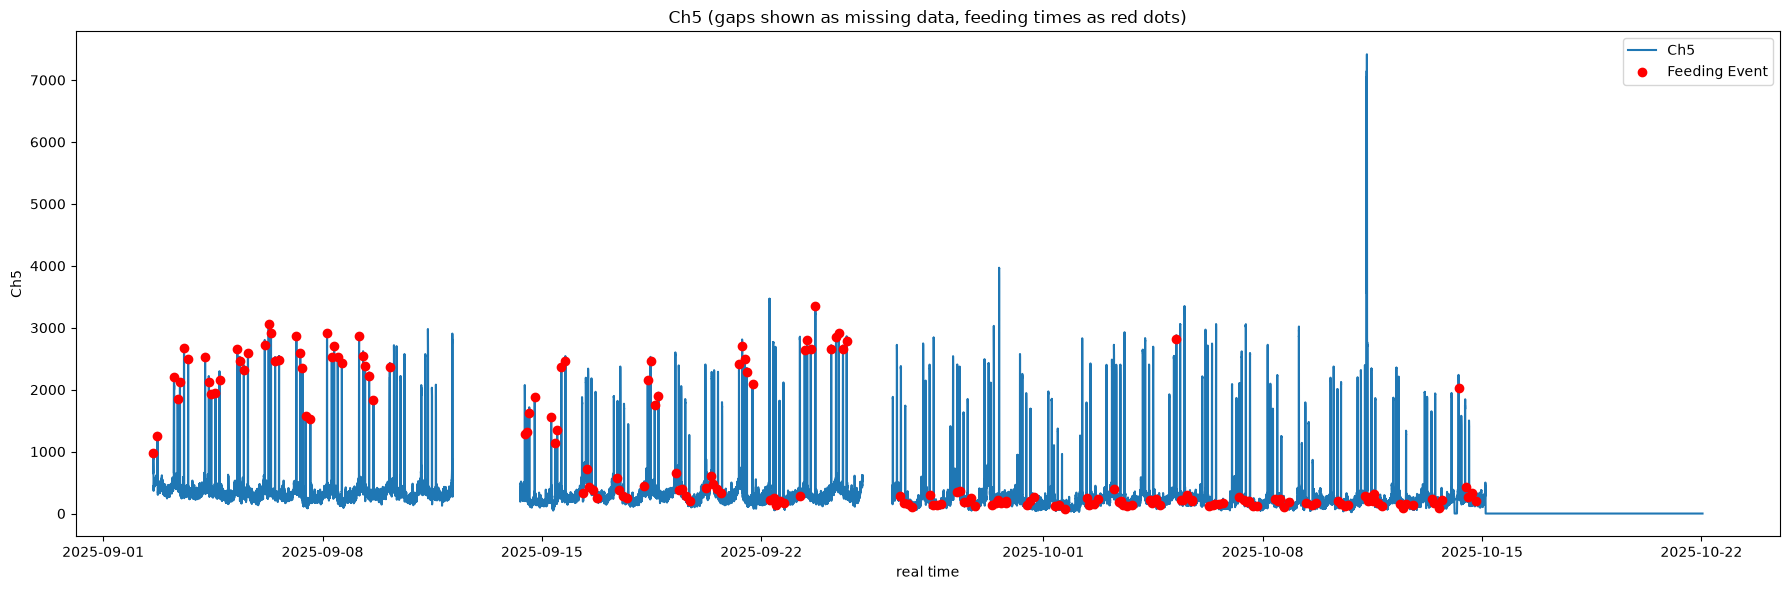

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# ----- CHANGE CHANNEL HERE -----
ch = 5  # Set to desired channel number (e.g., 4, 5, 6, etc.)
ch_col = f"Ch{ch}"
# --------------------------------

df_combo = df_combined.copy()
df_combo = df_combo.sort_values("real time")
df_combo['real time'] = pd.to_datetime(df_combo['real time'].astype(str), format="%Y%m%d%H%M%S")

# Load feeding times DataFrame
feeding_df = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\feeding_timed_combined.parquet")
feeding_times = pd.to_datetime(feeding_df['real time'].astype(str), format="%Y%m%d%H%M%S")

# Calculate the time difference between samples (in seconds)
time_diffs = df_combo["real time"].diff().dt.total_seconds()
expected_interval = 6
gap_mask = time_diffs > (expected_interval * 1.5)
# Insert NaN in selected channel for the rows after a gap to break the plot at gaps
ch_with_gaps = df_combo[ch_col].copy()
ch_with_gaps.loc[gap_mask] = np.nan

plt.figure(figsize=(18, 6))
plt.plot(df_combo["real time"], ch_with_gaps, label=ch_col)

# Overlay red dots at feeding "real time"s, at corresponding channel values (if available)
feeding_dot_times = []
feeding_dot_values = []
combo_time_to_ch = dict(zip(df_combo['real time'], ch_with_gaps))
for t in feeding_times:
    if t in combo_time_to_ch and not pd.isna(combo_time_to_ch[t]):
        feeding_dot_times.append(t)
        feeding_dot_values.append(combo_time_to_ch[t])
plt.scatter(feeding_dot_times, feeding_dot_values, color='red', label="Feeding Event", zorder=10)

plt.ylabel(ch_col)
plt.xlabel("real time")
plt.title(f"{ch_col} (gaps shown as missing data, feeding times as red dots)")
plt.legend()
plt.tight_layout()
plt.show()

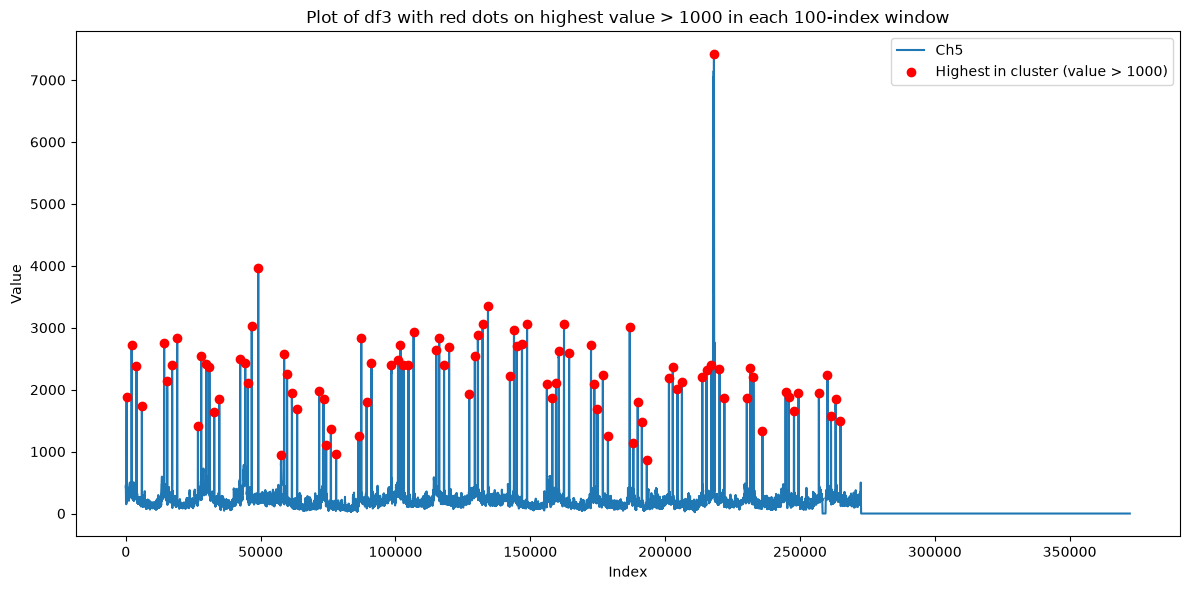

92


In [136]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Plot Ch5
plt.figure(figsize=(12, 6))
ax = plt.gca()
df_3['Ch5'].plot(ax=ax)

red_dot_indices = []
red_dot_values = []
red_dot_times = []

if 'Ch5' in df_3.columns:
    y = df_3['Ch5'].values
    idx = np.arange(len(y))
    mask_above_1000 = y > 850
    idx_above = idx[mask_above_1000]

    if len(idx_above) > 0:
        group = [idx_above[0]]
        for i in range(1, len(idx_above)):
            if idx_above[i] - idx_above[i - 1] <= 100:
                group.append(idx_above[i])
            else:
                group_vals = y[group]
                argmax = np.argmax(group_vals)
                max_idx = group[argmax]
                red_dot_indices.append(max_idx)
                red_dot_values.append(y[max_idx])
                # Save real time for this max value
                if "real time" in df_3.columns:
                    red_dot_times.append(df_3.iloc[max_idx]["real time"])
                group = [idx_above[i]]
        if group:
            group_vals = y[group]
            argmax = np.argmax(group_vals)
            max_idx = group[argmax]
            red_dot_indices.append(max_idx)
            red_dot_values.append(y[max_idx])
            if "real time" in df_3.columns:
                red_dot_times.append(df_3.iloc[max_idx]["real time"])

    plt.scatter(red_dot_indices, red_dot_values, color='red', label='Highest in cluster (value > 1000)', zorder=10)

plt.title("Plot of df3 with red dots on highest value > 1000 in each 100-index window")
plt.xlabel("Index")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

print(len(red_dot_indices))

# Save the N red dot "real time"s (that correspond to the max value of each cluster) to the specified parquet file
if red_dot_times:
    feeding_times_row3 = pd.Series(red_dot_times, name="real time")
    feeding_times_row3.to_frame().reset_index(drop=True).to_parquet(
        r"H:\Exp_Ein_Hamifratz\output_111026\feeding_times_row3.parquet"
    )

In [130]:
len(red_dot_indices)

372426

In [119]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the three rows with "real time"
row1 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row1_with_realtime_0.01.parquet")
row2 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row2_with_realtime_0.01.parquet")
row3 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\row3_with_realtime_0.01.parquet")
combined = pd.concat([row1.assign(row=1), row2.assign(row=2), row3.assign(row=3)], axis=0, ignore_index=True)


In [121]:
# Create "time" column from "real time" (YYYYMMDDHHMMSS)
combined = combined.copy()
combined["time"] = pd.to_datetime(combined["real time"].astype(str), format="%Y%m%d%H%M%S")
combined

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,time,real time,row
0,0,1,0,2,7,23,2025-09-02 14:15:00,20250902141500,1
1,0,1,0,2,7,23,2025-09-02 14:15:06,20250902141506,1
2,0,1,0,2,7,23,2025-09-02 14:15:12,20250902141512,1
3,0,1,0,2,7,23,2025-09-02 14:15:18,20250902141518,1
4,0,1,0,2,7,23,2025-09-02 14:15:24,20250902141524,1
...,...,...,...,...,...,...,...,...,...
667398,1,1,0,0,0,0,2025-10-22 00:52:36,20251022005236,3
667399,1,1,0,0,0,0,2025-10-22 00:52:42,20251022005242,3
667400,1,1,0,0,0,0,2025-10-22 00:52:48,20251022005248,3
667401,1,1,0,0,0,0,2025-10-22 00:52:54,20251022005254,3


In [137]:

# Load the feeding times (as DataFrames) and combine them one below the other
feed1 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\feeding_times_row1.parquet")
feed2 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\feeding_times_row2.parquet")
feed3 = pd.read_parquet(r"H:\Exp_Ein_Hamifratz\output_111026\feeding_times_row3.parquet")
# Combine the three feeding time DataFrames in order into a single Series, one after another
feeding_times_combined = pd.concat([feed1.squeeze(), feed2.squeeze(), feed3.squeeze()], ignore_index=True)


In [138]:
# feeding_times_combined values are YYYYMMDDHHMMSS (int or str); convert to Timestamp for inspection
feeding_times_combined_dt = pd.to_datetime(feeding_times_combined.astype(str), format="%Y%m%d%H%M%S")
feeding_times_combined_dt.head()

0   2025-09-02 14:20:36
1   2025-09-02 17:35:36
2   2025-09-03 06:15:06
3   2025-09-03 10:46:30
4   2025-09-03 13:54:36
Name: real time, dtype: datetime64[us]

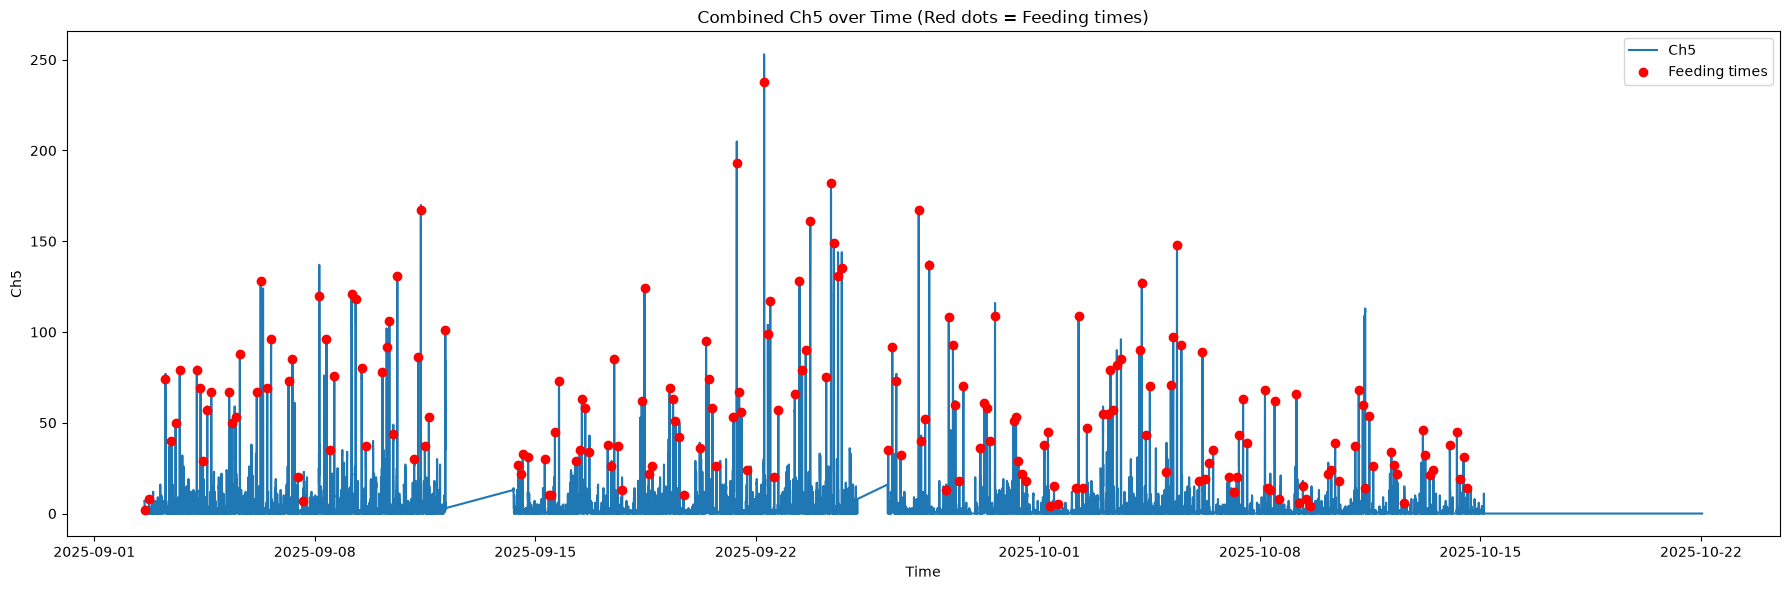

In [139]:
import matplotlib.pyplot as plt

# Plot combined Ch5, with time as x axis
plt.figure(figsize=(18,6))
plt.plot(combined['time'], combined['Ch5'], label="Ch5")

# For red dots at feeding times, get the Ch5 value at each feeding time
feeding_ch5_at_times = combined.set_index('time').reindex(feeding_times_combined_dt)['Ch5']

plt.scatter(feeding_times_combined_dt, 
            feeding_ch5_at_times, 
            color='red', label="Feeding times", zorder=5)

plt.xlabel("Time")
plt.ylabel("Ch5")
plt.title("Combined Ch5 over Time (Red dots = Feeding times)")
plt.legend()
plt.tight_layout()
plt.show()

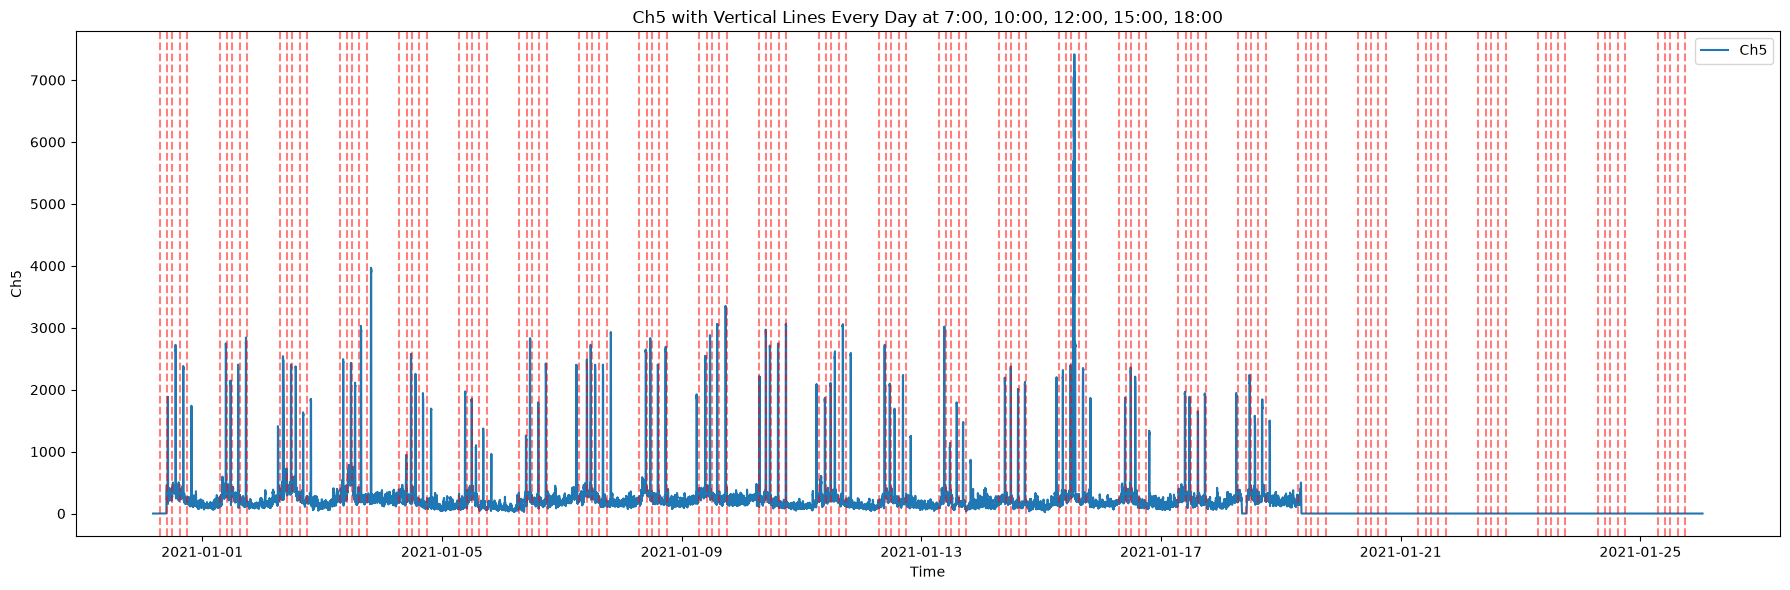

In [63]:
import matplotlib.pyplot as plt

# Make sure 'time' column is datetime
df['time'] = pd.to_datetime(df['time'])

fig, ax = plt.subplots(figsize=(18,6))
ax.plot(df['time'], df['Ch5'], label="Ch5")

# Add a red vertical line every day at 7:00, 10:00, 12:00, 15:00, 18:00
times_of_day = ["07:00:00", "10:00:00", "12:00:00", "15:00:00", "18:00:00"]

# Get the unique dates in the df['time'] column
unique_dates = df['time'].dt.normalize().unique()

for date in unique_dates:
    for tod in times_of_day:
        line_time = pd.Timestamp(date) + pd.to_timedelta(tod)
        # If this timestamp is within the data's range, plot the vline
        if df['time'].min() <= line_time <= df['time'].max():
            ax.axvline(line_time, color='red', linestyle='--', alpha=0.5)

ax.set_title("Ch5 with Vertical Lines Every Day at 7:00, 10:00, 12:00, 15:00, 18:00")
ax.set_xlabel("Time")
ax.set_ylabel("Ch5")
ax.legend()
plt.tight_layout()
plt.show()

In [31]:
import pandas as pd

# Load the provided Parquet file into a DataFrame
feeding_df = pd.read_parquet(r"D:\Exp_Ein_Hamifratz\MF_in_a_row_2\output\feeding_timed_df_grouped_sr2.parquet")

# Optionally display the first few rows for quick inspection
feeding_df.head()

,index time,value,real time
0,2118,1948,20250914105148
1,3147,1555,20250914123442
2,4184,1634,20250914141824
3,6665,1767,20250914182630
4,14269,1476,20250915070654


In [15]:
import pandas as pd

# Load the provided Parquet file into a DataFrame
feeding_df = pd.read_parquet(r"D:\Exp_Ein_Hamifratz\MF_in_a_row_3\output\feeding_timed_df_grouped_sr3.parquet")

# Optionally display the first few rows for quick inspection
feeding_df.head()

,index time,value,real time
0,3486,1785,20250926100836
1,5374,2552,20250926131724
2,7200,2263,20250926162000
3,9160,1675,20250926193600
4,17441,2595,20250927092406


In [91]:
df1 = df1.rename(columns={
    'Ch0': 'Ch1',
    'Ch1': 'Ch2',
    'Ch2': 'Ch3',
    'Ch3': 'Ch4',
    'Ch4': 'Ch5',
    'Ch5': 'Ch6'
})
df1_renamed

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,real time
0,21,86,10,66,202,181,20250902141500
1,21,81,10,65,196,177,20250902141506
2,21,82,10,53,196,176,20250902141512
3,21,84,12,50,196,176,20250902141518
4,21,83,12,50,197,177,20250902141524
...,...,...,...,...,...,...,...
109466,74,118,116,127,104,54,20250910044136
109467,74,118,115,121,104,54,20250910044142
109468,74,119,115,121,104,49,20250910044148
109469,73,120,115,121,104,49,20250910044154


In [ ]:
#df1 = pd.read_parquet(r"D:\Exp_Ein_Hamifratz\0209-1009\row1_with_realtime.parquet")
df2 = pd.read_parquet(r"D:\Exp_Ein_Hamifratz\MF_in_a_row_2\output\row2_with_realtime.parquet")
df3 = pd.read_parquet(r"D:\Exp_Ein_Hamifratz\MF_in_a_row_3\output\row3_with_realtime.parquet")

In [92]:
# Concatenate df1, df2, and df3 with their 'real time' columns, stacking them vertically
combined_df = pd.concat([df1, df2, df3], ignore_index=True)
combined_df = combined_df.drop(columns=['time'])

# Save the combined DataFrame to a Parquet file
combined_df.to_parquet(r"D:\Exp_Ein_Hamifratz\combined_df_with_realtime.parquet")

# Display the first few rows of the combined DataFrame
combined_df.head()

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,real time
0,21,86,10,66,202,181,20250902141500
1,21,81,10,65,196,177,20250902141506
2,21,82,10,53,196,176,20250902141512
3,21,84,12,50,196,176,20250902141518
4,21,83,12,50,197,177,20250902141524


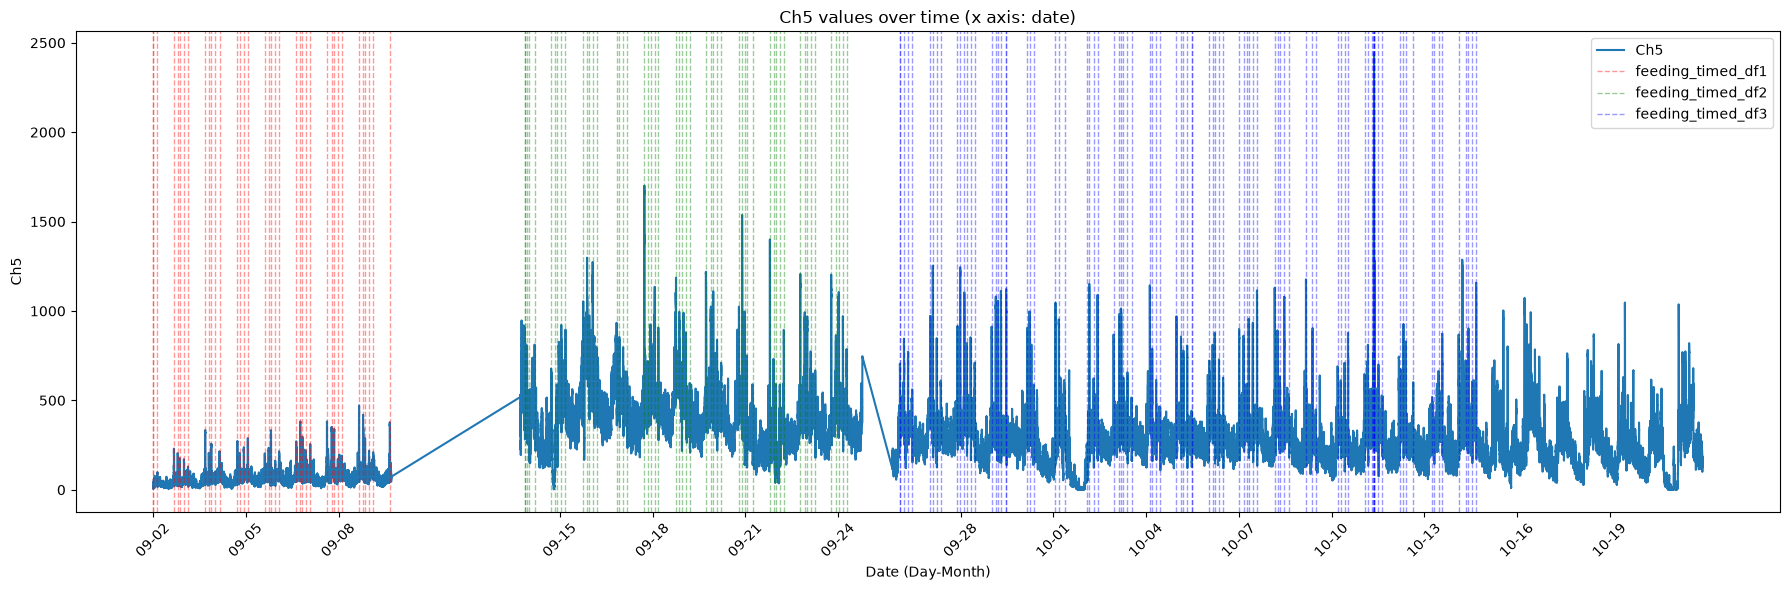

In [95]:
# plot combined_df Ch5 with real time as x axis only the day and month, with vertical lines for feeding_timed_df1, 2, 3
import matplotlib.pyplot as plt

# Convert real time to datetime
combined_df['real time'] = pd.to_datetime(combined_df['real time'], format="%Y%m%d%H%M%S")

# Extract just day and month for x-axis labeling
combined_df['real_time_dm'] = combined_df['real time'].dt.strftime("%m-%d")

plt.figure(figsize=(18, 6))
plt.plot(combined_df['real time'], combined_df['Ch1'], label='Ch5')
plt.xlabel("Date (Day-Month)")
plt.ylabel("Ch5")
plt.title("Ch5 values over time (x axis: date)")

plt.xticks(
    ticks=combined_df['real time'][::len(combined_df)//15],  # show only some ticks, else overlap
    labels=combined_df['real_time_dm'][::len(combined_df)//15],
    rotation=45
)

# Add vertical lines for the real time of each event in the feeding_timed_df1, 2, 3
for idx, (feeding_timed_df, color, label) in enumerate(
    zip(
        [feeding_timed_df1, feeding_timed_df2, feeding_timed_df3],
        ['r', 'g', 'b'],
        ['feeding_timed_df1', 'feeding_timed_df2', 'feeding_timed_df3']
    )
):
    # Ensure we have the correct columns and datetimes
    if 'real time' in feeding_timed_df.columns:
        times = pd.to_datetime(feeding_timed_df['real time'], format='%Y%m%d%H%M%S')
        for t in times:
            plt.axvline(x=t, color=color, linestyle='--', alpha=0.4, lw=1)
        # Add only one legend entry per source
        plt.axvline(
            x=times.iloc[0], color=color, linestyle='--', alpha=0.4, lw=1,
            label=label
        )

plt.tight_layout()
plt.legend()
plt.show()

In [69]:
# Load the specified DataFrames from the given Parquet file paths
feeding_timed_df1 = pd.read_parquet(r"D:\Exp_Ein_Hamifratz\0209-1009\feeding_timed_df_grouped.parquet")
feeding_timed_df2 = pd.read_parquet(r"D:\Exp_Ein_Hamifratz\MF_in_a_row_2\output\feeding_timed_df_grouped_sr2.parquet")
feeding_timed_df3 = pd.read_parquet(r"D:\Exp_Ein_Hamifratz\MF_in_a_row_3\output\feeding_timed_df_grouped_sr3.parquet")

# Combine the dataframes (add a column to identify group/source)
feeding_timed_df1['source'] = 'group1'
feeding_timed_df2['source'] = 'group2'
feeding_timed_df3['source'] = 'group3'

feeding_timed_combined = pd.concat(
    [feeding_timed_df1, feeding_timed_df2, feeding_timed_df3],
    ignore_index=True
)

# Save the combined dataframe to disk as Parquet
feeding_timed_combined.to_parquet(r"D:\Exp_Ein_Hamifratz\feeding_timed_combined.parquet")

# Display the first few rows to inspect
feeding_timed_combined.head()

,index time,value,real time,source
0,55,591,20250902142036,group1
1,2009,803,20250902173600,group1
2,9598,842,20250903061454,group1
3,11284,565,20250903090330,group1
4,12303,610,20250903104524,group1


In [70]:
len(feeding_timed_combined)

182

In [103]:
import numpy as np

# Assume 'combined_df' is the main time-series data DataFrame (e.g., channels, time, etc.)
# Assume 'feeding_timed_combined' has the 'real time' column with event times corresponding to the time in 'combined_df'

# Ensure combined_df['real time'] is datetime to match with feeding_timed_combined['real time'] if necessary
if 'real time' in combined_df.columns and np.issubdtype(combined_df['real time'].dtype, np.number):
    combined_df['real time'] = pd.to_datetime(combined_df['real time'].astype(str), format='%Y%m%d%H%M%S')
elif 'real time' in combined_df.columns:
    combined_df['real time'] = pd.to_datetime(combined_df['real time'])
else:
    raise ValueError("combined_df must have a 'real time' column.")

# If necessary, convert feeding_timed_combined['real time'] to datetime
feeding_timed_combined['real time'] = pd.to_datetime(feeding_timed_combined['real time'], format='%Y%m%d%H%M%S')

window = 50  # rows before and after

results = []

for _, row in feeding_timed_combined.iterrows():
    event_time = row['real time']
    # Find the closest row in combined_df to this event_time
    idx = (combined_df['real time'] - event_time).abs().idxmin()
    start_idx = max(idx - window, 0)
    end_idx = min(idx + window + 1, len(combined_df))
    window_df = combined_df.iloc[start_idx:end_idx]
    
    # Find channel columns (excluding time columns)
    channel_cols = [col for col in combined_df.columns if col.lower().startswith('ch')]
    max_vals = window_df[channel_cols].max()
    
    result_row = {
        'feeding_time': event_time,
        **{f'max_{ch}': max_vals[ch] for ch in channel_cols}
    }
    results.append(result_row)

# Create DataFrame from results
max_around_feeding_df = pd.DataFrame(results)

# Display the first few rows of the result
max_around_feeding_df.head()
len(max_around_feeding_df)

# Calculate the average (mean) for each channel column in max_around_feeding_df
# Compute average (mean) per day per channel from max_around_feeding_df

# Extract the date from the 'feeding_time' column
max_around_feeding_df['date'] = max_around_feeding_df['feeding_time'].dt.date

# Select columns that start with 'max_' (the channels to average)
max_channel_cols = [col for col in max_around_feeding_df.columns if col.startswith('max_')]

# Group by date and compute the mean for each max_ channel
average_per_day_per_channel = max_around_feeding_df.groupby('date')[max_channel_cols].mean()
# (Columns are max_Ch1, max_Ch2, ...; rows are days)

# If you want to view the average per channel per day:
average_per_day_per_channel.head()

,max_Ch1,max_Ch2,max_Ch3,max_Ch4,max_Ch5,max_Ch6
date,,,,,,
2025-09-02,55.5,172.5,35.50,138.0,502.0,718.50
2025-09-03,182.6,243.2,174.60,379.2,1012.6,707.00
2025-09-04,221.8,235.6,223.00,413.0,1037.6,672.00
2025-09-05,245.0,255.0,261.75,429.5,1246.5,945.25
2025-09-06,229.4,296.8,245.20,471.6,1318.2,1070.60


In [130]:
import numpy as np

# Ensure datetime format for 'real time' columns
if 'real time' in combined_df.columns and np.issubdtype(combined_df['real time'].dtype, np.number):
    combined_df['real time'] = pd.to_datetime(combined_df['real time'].astype(str), format='%Y%m%d%H%M%S')
elif 'real time' in combined_df.columns:
    combined_df['real time'] = pd.to_datetime(combined_df['real time'])
else:
    raise ValueError("combined_df must have a 'real time' column.")

feeding_timed_combined['real time'] = pd.to_datetime(feeding_timed_combined['real time'], format='%Y%m%d%H%M%S')

window = 50  # rows before and after

per_feeding_results = []

# Feeding hours in day
feeding_hours = [7, 10, 12, 15, 18]

# Function to classify each feeding event to its closest feeding slot (force assignment for all)
def force_feeding_slot(dt):
    # For each feeding hour: create a datetime for that day at feeding hour, minute=0, second=0
    feeding_times = [dt.replace(hour=h, minute=0, second=0, microsecond=0) for h in feeding_hours]
    # Compute the absolute time difference in seconds from feeding event to each slot
    time_deltas = [abs((dt - slot_time).total_seconds()) for slot_time in feeding_times]
    # Return the hour with the minimum difference (always one slot, never empty)
    return feeding_hours[np.argmin(time_deltas)]

for _, row in feeding_timed_combined.iterrows():
    event_time = row['real time']
    idx = (combined_df['real time'] - event_time).abs().idxmin()
    start_idx = max(idx - window, 0)
    end_idx = min(idx + window + 1, len(combined_df))
    window_df = combined_df.iloc[start_idx:end_idx]
    
    channel_cols = [col for col in combined_df.columns if col.lower().startswith('ch')]
    max_vals = window_df[channel_cols].max()
    slot = force_feeding_slot(event_time)  # Ensures every event has a feeding slot
    date = event_time.date()
    
    result_row = {
        'date': date,
        'feeding_slot': slot,
        'feeding_time': event_time,
        **{f'max_{ch}': max_vals[ch] for ch in channel_cols}
    }
    per_feeding_results.append(result_row)

# Create DataFrame from results
per_feeding_df = pd.DataFrame(per_feeding_results)

# Per day per feeding: group by date and feeding_slot
max_channel_cols = [col for col in per_feeding_df.columns if col.startswith('max_')]
per_day_per_feeding = (
    per_feeding_df.groupby(['date', 'feeding_slot'])[max_channel_cols]
    .mean()
    .reset_index()
)

per_day_per_feeding.head()

,date,feeding_slot,max_Ch1,max_Ch2,max_Ch3,max_Ch4,max_Ch5,max_Ch6
0,2025-09-02,15,23.0,139.0,29.0,70.0,428.0,569.0
1,2025-09-02,18,88.0,206.0,42.0,206.0,576.0,868.0
2,2025-09-03,7,230.0,349.0,226.0,469.0,904.0,948.0
3,2025-09-03,10,191.0,234.5,175.5,450.5,860.5,578.5
4,2025-09-03,15,171.0,233.0,170.0,295.0,1299.0,779.0


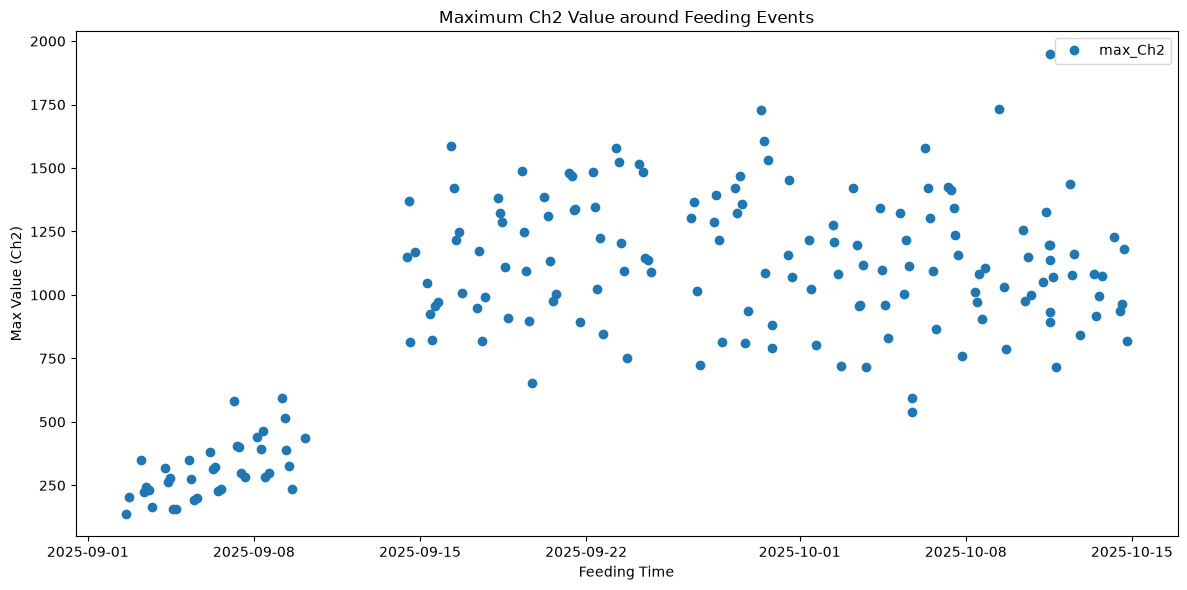

In [101]:
import matplotlib.pyplot as plt

# Set which channel to plot (e.g., 5 for Ch5, 2 for Ch2, etc.)
channel_to_plot = 2  # Change this value as needed, e.g., 2 for Ch2

# Plot only the selected channel as dots around each feeding event
fig, ax = plt.subplots(figsize=(12, 6))

# Find the relevant column for the selected channel (e.g., 'max_Ch5')
max_col = next(
    c for c in max_around_feeding_df.columns 
    if c.lower() == f"max_ch{channel_to_plot}"
)

ax.plot(
    max_around_feeding_df['feeding_time'],
    max_around_feeding_df[max_col],
    'o',  # dot markers
    label=f'max_Ch{channel_to_plot}',
    linestyle='None'  # no line connecting dots
)

ax.set_xlabel('Feeding Time')
ax.set_ylabel(f'Max Value (Ch{channel_to_plot})')
ax.set_title(f'Maximum Ch{channel_to_plot} Value around Feeding Events')
ax.legend()
plt.tight_layout()
plt.show()

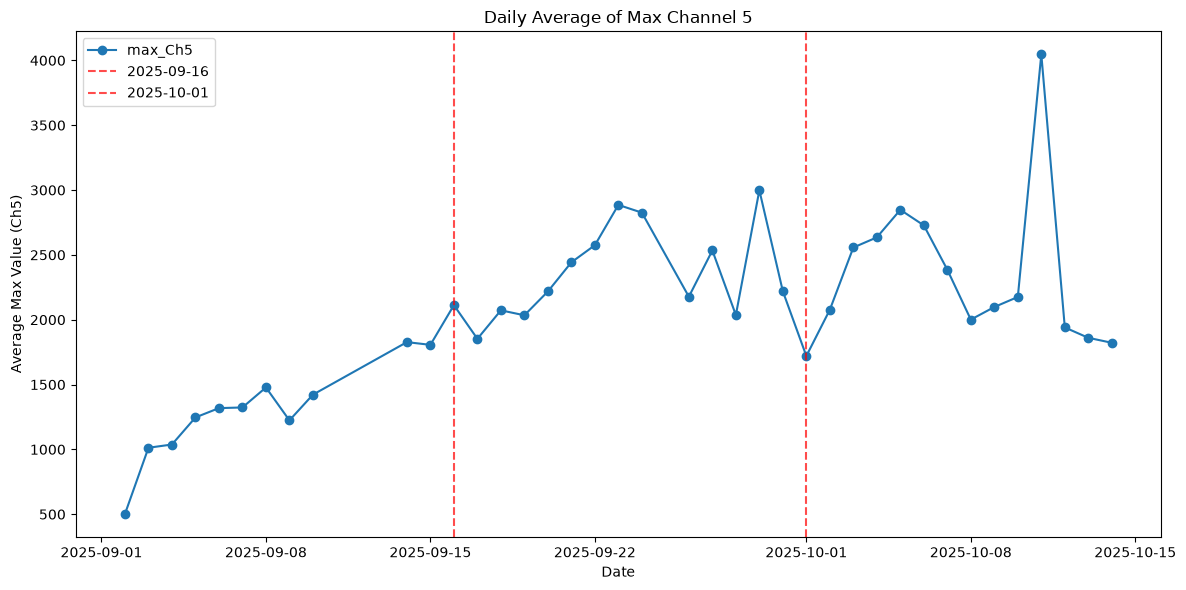

In [115]:
import matplotlib.pyplot as plt

# Set the channel to plot (e.g., 1 for Ch1, 2 for Ch2, etc.)
channel_to_plot = 5  # Change as needed

colname = f"max_Ch{channel_to_plot}"
ax = average_per_day_per_channel[colname].plot(
    marker='o', 
    figsize=(12, 6), 
    title=f'Daily Average of Max Channel {channel_to_plot}'
)
ax.set_xlabel('Date')
ax.set_ylabel(f'Average Max Value (Ch{channel_to_plot})')

# Add vertical lines at 16.09 and 01.10
for date_str in ['2025-09-16', '2025-10-01']:
    ax.axvline(pd.to_datetime(date_str), color='red', linestyle='--', alpha=0.7, label=f'{date_str}')

# Show legend only once for vertical lines
handles, labels = ax.get_legend_handles_labels()
if len(handles) > 1:
    from collections import OrderedDict
    by_label = OrderedDict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys())
else:
    ax.legend()

plt.tight_layout()
plt.show()

In [131]:
per_day_per_feeding

,date,feeding_slot,max_Ch1,max_Ch2,max_Ch3,max_Ch4,max_Ch5,max_Ch6
0,2025-09-02,15,23.0,139.0,29.0,70.0,428.0,569.0
1,2025-09-02,18,88.0,206.0,42.0,206.0,576.0,868.0
2,2025-09-03,7,230.0,349.0,226.0,469.0,904.0,948.0
3,2025-09-03,10,191.0,234.5,175.5,450.5,860.5,578.5
4,2025-09-03,15,171.0,233.0,170.0,295.0,1299.0,779.0
...,...,...,...,...,...,...,...,...
154,2025-10-13,18,873.0,1073.0,370.0,1391.0,1940.0,3427.0
155,2025-10-14,7,868.0,1230.0,256.0,1820.0,1947.0,3121.0
156,2025-10-14,12,724.0,938.0,316.0,1655.0,2239.0,3431.0
157,2025-10-14,15,753.5,1072.0,458.0,1158.0,1711.5,3142.0


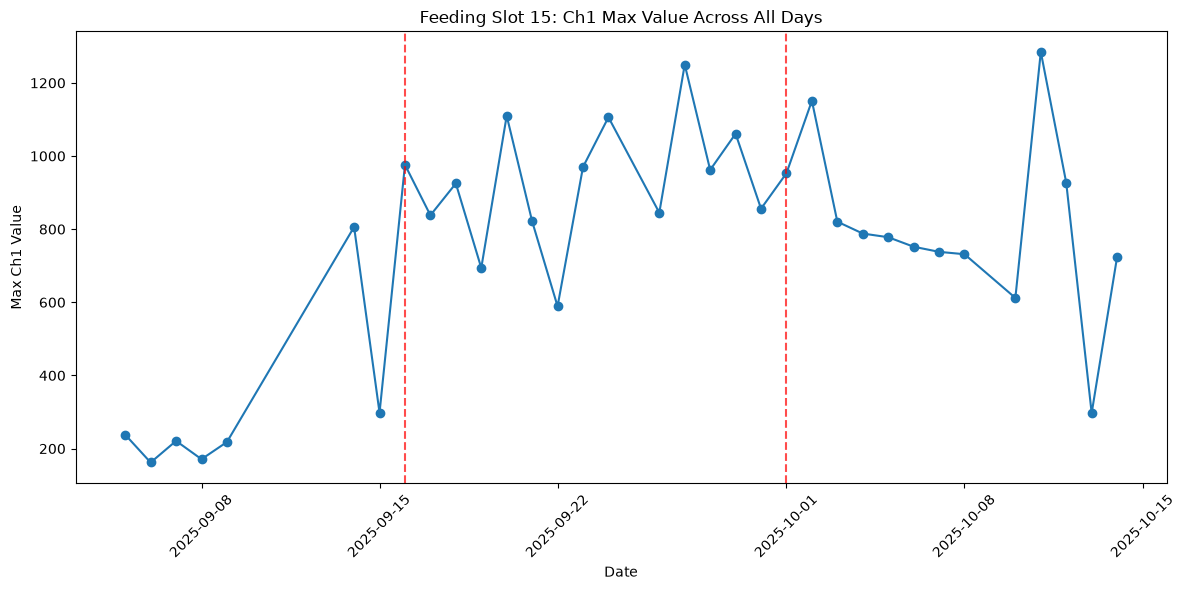

In [142]:
import matplotlib.pyplot as plt

# Filter for feeding_slot 15 and get Ch1 values for all days
slot_15_ch1 = per_day_per_feeding[per_day_per_feeding['feeding_slot'] == 12]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(slot_15_ch1['date'], slot_15_ch1['max_Ch1'], marker='o', linestyle='-')
# Add vertical lines at 16.09 and 01.10
for date_str in ['2025-09-16', '2025-10-01']:
    ax.axvline(pd.to_datetime(date_str), color='red', linestyle='--', alpha=0.7, label=f'{date_str}')
ax.set_xlabel('Date')
ax.set_ylabel('Max Ch1 Value')
ax.set_title('Feeding Slot 15: Ch1 Max Value Across All Days')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()